<a href="https://colab.research.google.com/github/onishchenkoanastasia5-glitch/Machine_learning/blob/main/%D0%9B%D0%A04_%D0%9E%D0%BD%D0%B8%D1%89%D0%B5%D0%BD%D0%BA%D0%BE_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Студентка:Онищенко Анастасія
Група:ФІТ 3-2

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [2]:
dataset_dir = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_file = glob.glob(os.path.join(dataset_dir, "*.csv"))[0]
print("CSV файл:", csv_file)

data = pd.read_csv(csv_file)
data.head()

100%|██████████| 18.1k/18.1k [00:00<00:00, 19.2MB/s]

Extracting files...
CSV файл: /root/.cache/kagglehub/datasets/hellbuoy/car-price-prediction/versions/1/CarPrice_Assignment.csv


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
rows, cols = data.shape
print(f"Об'єктів: {rows}, ознак: {cols}")
print("Стовпці:", data.columns.tolist())

Об'єктів: 205, ознак: 26
Стовпці: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [5]:
TARGET = "price"
print("Цільова змінна:", TARGET)
data.describe()

Цільова змінна: price


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


Висновок: у датасеті 205 автомобілів і 26 стовпців. Цільова змінна price, це неперервне число. Ціни від 5118 до 45400, середня приблизно 13277. Стовпець car_ID це просто номер автомобіля, він не є характеристикою.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:
print("Пропусків у кожному стовпці:")
print(data.isna().sum()[data.isna().sum() > 0])
print("Разом пропусків:", data.isna().sum().sum())

Пропусків у кожному стовпці:
Series([], dtype: int64)
Разом пропусків: 0


In [7]:
print("Повні дублікати:", data.duplicated().sum())

# car_ID у кожного рядка свій, тому перевіряємо дублікати без нього
features_only = data.drop(columns=["car_ID"])
print("Дублікати без car_ID:", features_only.duplicated().sum())

Повні дублікати: 0
Дублікати без car_ID: 0


In [8]:
unique_counts = data.nunique().to_frame("Унікальних значень")
unique_counts["Тип"] = data.dtypes.astype(str)
unique_counts.sort_values("Унікальних значень")

,Унікальних значень,Тип
fueltype,2,object
aspiration,2,object
doornumber,2,object
enginelocation,2,object
drivewheel,3,object
carbody,5,object
symboling,6,int64
cylindernumber,7,object
enginetype,7,object
fuelsystem,8,object


### Перевірка CarName

У CarName 147 різних значень, тобто майже кожне авто має свою назву. Перше слово назви це марка. Перевіримо, які марки є в даних.

In [9]:
data["company"] = data["CarName"].apply(lambda name: name.split(" ")[0])
print(sorted(data["company"].unique()))
print("Кількість марок:", data["company"].nunique())

['Nissan', 'alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']
Кількість марок: 28


In [10]:
# підозрілі марки: схожі на інші з помилкою
check = data[data["company"].isin(["Nissan", "maxda", "porcshce", "toyouta", "vokswagen", "vw"])]
check[["car_ID", "CarName", "enginesize", "horsepower", "price"]]

,car_ID,CarName,enginesize,horsepower,price
50,51,maxda rx3,91,68,5195.0
51,52,maxda glc deluxe,91,68,6095.0
89,90,Nissan versa,97,69,5499.0
126,127,porcshce panamera,194,207,32528.0
181,182,toyouta tercel,161,156,15750.0
182,183,vokswagen rabbit,97,52,7775.0
189,190,vw dasher,109,90,11595.0
190,191,vw rabbit,109,90,9980.0


In [11]:
# сусідні рядки (дані впорядковані за марками)
for i in check.index:
    print(data.loc[i - 1, "CarName"], "|", data.loc[i, "CarName"], "|", data.loc[i + 1, "CarName"])

jaguar xk | maxda rx3 | maxda glc deluxe
maxda rx3 | maxda glc deluxe | mazda rx2 coupe
mitsubishi mirage g4 | Nissan versa | nissan gt-r
porsche macan | porcshce panamera | porsche cayenne
toyota starlet | toyouta tercel | vokswagen rabbit
toyouta tercel | vokswagen rabbit | volkswagen 1131 deluxe sedan
volkswagen dasher | vw dasher | vw rabbit
vw dasher | vw rabbit | volkswagen rabbit


In [12]:
corrections = {"maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
               "vokswagen": "volkswagen", "vw": "volkswagen"}

data["company"] = data["company"].str.lower()
data["company"] = data["company"].replace(corrections)
data = data.drop(columns=["CarName"])

print("Марок після виправлення:", data["company"].nunique())
data["company"].value_counts().head(10)

Марок після виправлення: 22


,count
company,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugeot,11


Висновок: пропусків і дублікатів у даних немає, навіть якщо не враховувати car_ID. CarName має 147 різних значень, тому з нього взято тільки марку (company). Деякі марки написані з помилками: maxda, porcshce, toyouta, vokswagen, vw і Nissan з великої літери. Це ті самі марки, бо назви моделей їм відповідають і ці рядки стоять серед авто своєї марки. Після виправлення залишилось 22 марки, а CarName видалено.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [13]:
ids = data["car_ID"]
print("Збережено car_ID:", ids.shape[0], "значень")
print("Дублікатів серед car_ID:", ids.duplicated().sum())

Збережено car_ID: 205 значень
Дублікатів серед car_ID: 0


Висновок: car_ID збережено окремо у змінній ids, всі 205 значень унікальні. Для навчання моделей він не використовується.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


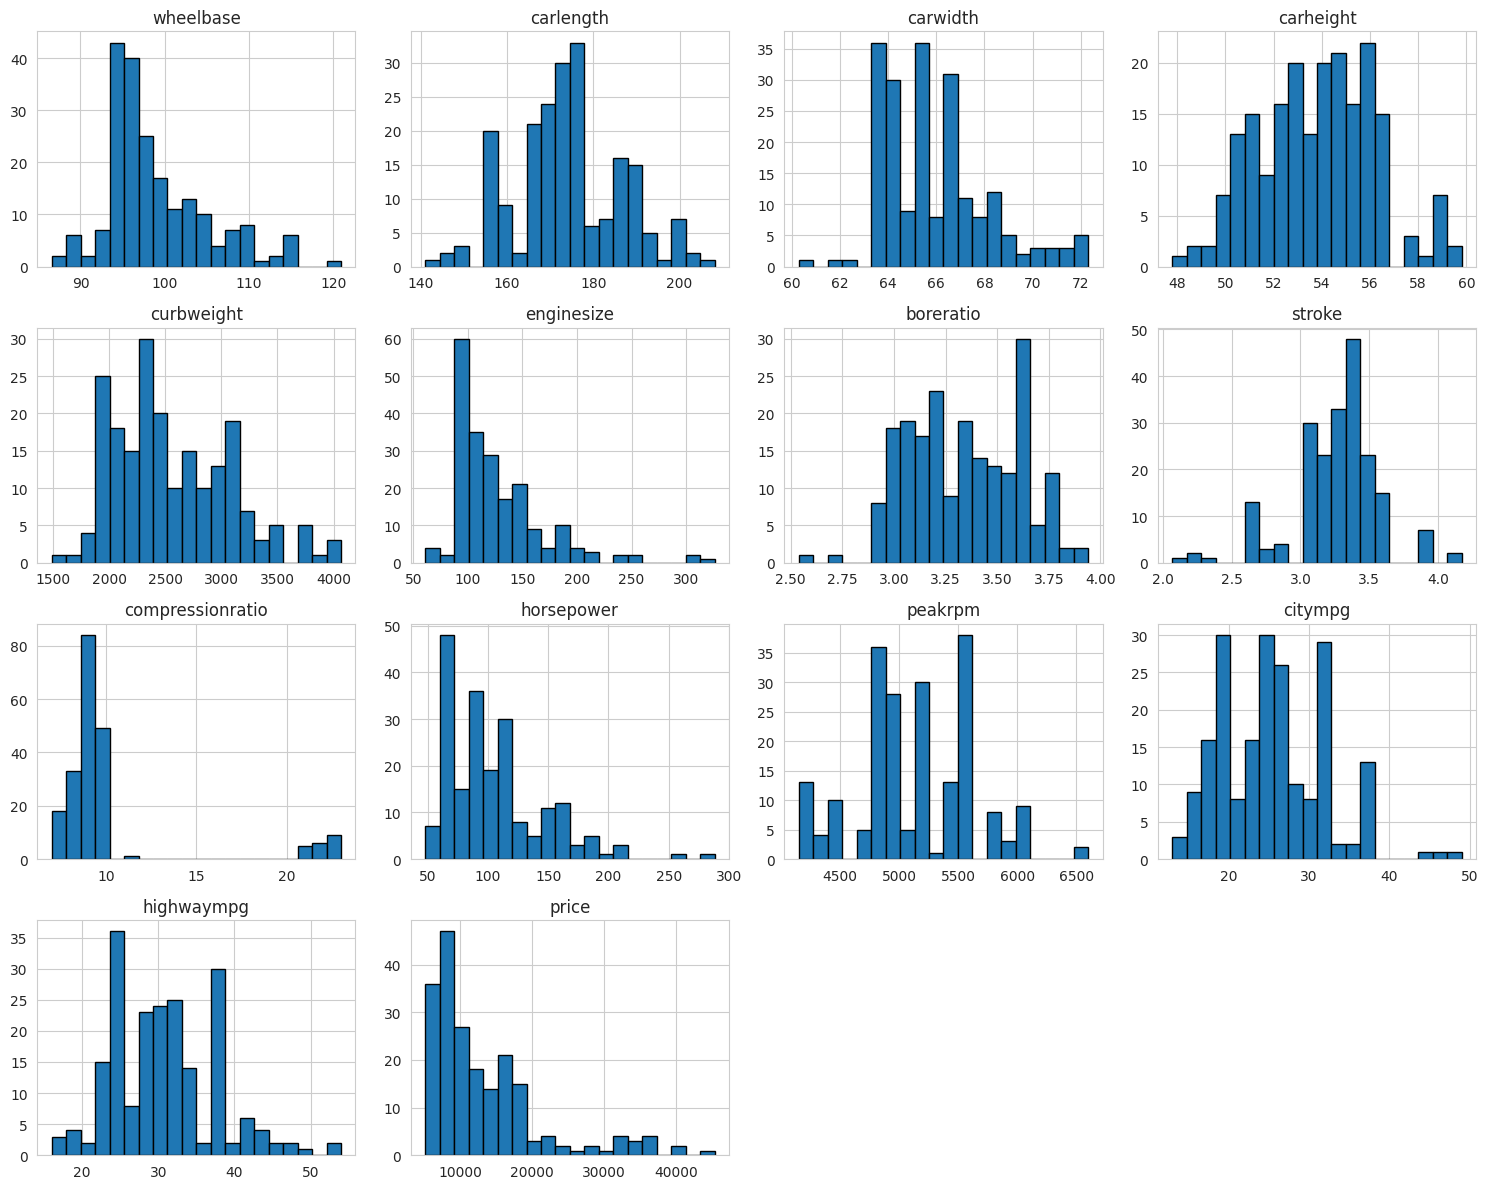

In [14]:
cont_features = ["wheelbase", "carlength", "carwidth", "carheight", "curbweight",
                 "enginesize", "boreratio", "stroke", "compressionratio",
                 "horsepower", "peakrpm", "citympg", "highwaympg"]

data[cont_features + ["price"]].hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

In [15]:
skewness = data[cont_features + ["price"]].skew().sort_values(key=abs, ascending=False)
skewness.to_frame("Коефіцієнт асиметрії").round(3)

,Коефіцієнт асиметрії
compressionratio,2.611
enginesize,1.948
price,1.778
horsepower,1.405
wheelbase,1.050
carwidth,0.904
stroke,-0.690
curbweight,0.681
citympg,0.664
highwaympg,0.540


In [16]:
print("Сильна асиметрія (|skew| > 1):", skewness[skewness.abs() > 1].index.tolist())
print("Помірна (0.5 - 1):", skewness[(skewness.abs() > 0.5) & (skewness.abs() <= 1)].index.tolist())

Сильна асиметрія (|skew| > 1): ['compressionratio', 'enginesize', 'price', 'horsepower', 'wheelbase']
Помірна (0.5 - 1): ['carwidth', 'stroke', 'curbweight', 'citympg', 'highwaympg']


Висновок: найбільша асиметрія у compressionratio (2.61), enginesize (1.95), horsepower (1.41), wheelbase (1.05) і у самій ціні price (1.78). Це права асиметрія: більшість авто мають невеликі значення, і лише кілька машин мають дуже великі. Інші ознаки майже симетричні або мають помірну асиметрію.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [17]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["car_ID", "price"])
y = data["price"]

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids, test_size=0.2, random_state=1
)
X_train, X_test = X_train.copy(), X_test.copy()

print("Train:", len(X_train), "Test:", len(X_test))

Train: 164 Test: 41


Висновок: дані поділено на 164 рядки для навчання і 41 для тесту. Для відтворюваності використано random_state=1. car_ID також поділено разом з даними (ids_train і ids_test).

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [18]:
def iqr_limits(column):
    q1, q3 = column.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

limits = {}
counts = {}
for col in cont_features:
    low, high = iqr_limits(X_train[col])   # тільки train
    limits[col] = (low, high)
    counts[col] = ((X_train[col] < low) | (X_train[col] > high)).sum()

pd.Series(counts).sort_values(ascending=False).to_frame("Викидів у train")

,Викидів у train
compressionratio,22
stroke,18
carwidth,8
horsepower,6
enginesize,6
wheelbase,3
highwaympg,2
peakrpm,2
citympg,1
curbweight,0


In [19]:
for col, (low, high) in limits.items():
    X_train[col] = X_train[col].clip(low, high)
    X_test[col] = X_test[col].clip(low, high)   # ті самі межі для test

print("Обмеження виконано. Рядків у train:", len(X_train))

Обмеження виконано. Рядків у train: 164


Висновок: найбільше викидів у compressionratio (22), stroke (18) і carwidth (8). Даних мало, тому рядки не видалялись. Значення, які виходять за межі IQR, замінено на ці межі. Межі пораховано тільки за train і застосовано до test.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


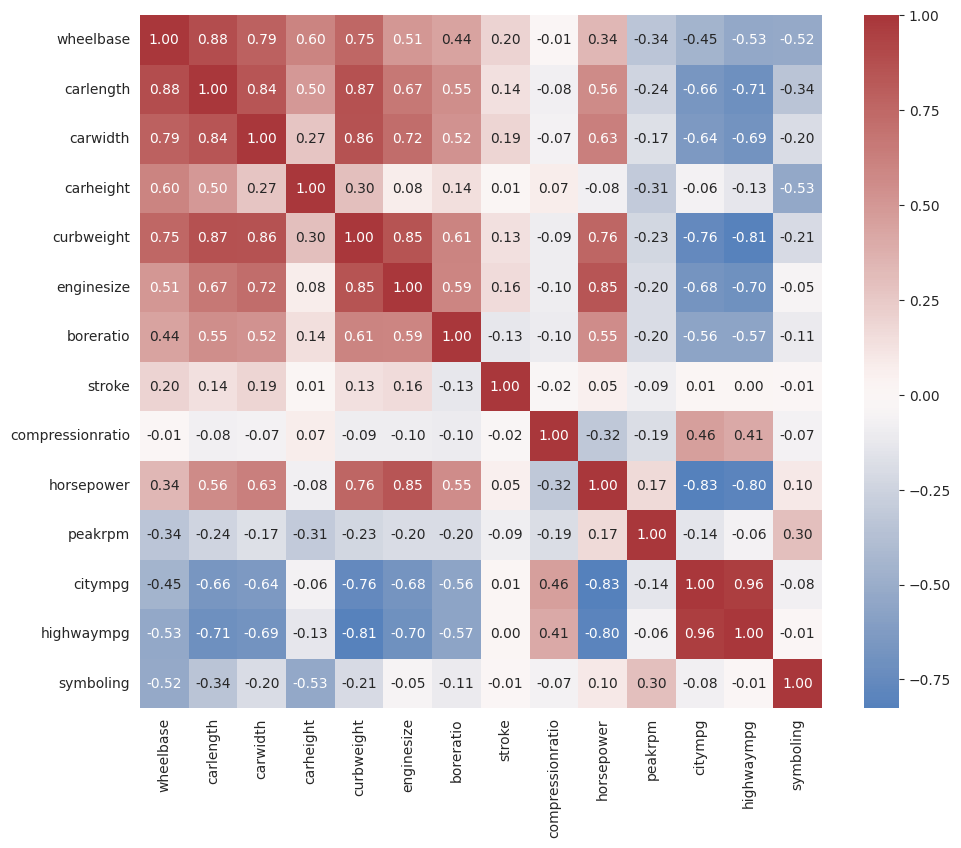

In [20]:
num_cols = cont_features + ["symboling"]
corr = X_train[num_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", annot=True, fmt=".2f", center=0)
plt.show()

In [21]:
price_corr = X_train[num_cols].corrwith(y_train).abs()

strong_pairs = []
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        if abs(corr.loc[a, b]) > 0.85:
            strong_pairs.append((a, b, round(corr.loc[a, b], 3)))

strong_pairs = sorted(strong_pairs, key=lambda t: -abs(t[2]))
for a, b, r in strong_pairs:
    print(f"{a} - {b}: r = {r}   (зв'язок з price: {price_corr[a]:.3f} / {price_corr[b]:.3f})")

citympg - highwaympg: r = 0.964   (зв'язок з price: 0.689 / 0.709)
wheelbase - carlength: r = 0.881   (зв'язок з price: 0.528 / 0.660)
carlength - curbweight: r = 0.87   (зв'язок з price: 0.660 / 0.827)
carwidth - curbweight: r = 0.864   (зв'язок з price: 0.751 / 0.827)
curbweight - enginesize: r = 0.853   (зв'язок з price: 0.827 / 0.865)


In [22]:
drop_cols = []
for a, b, r in strong_pairs:
    if a in drop_cols or b in drop_cols:
        continue
    drop_cols.append(a if price_corr[a] < price_corr[b] else b)

print("Видаляємо:", drop_cols)

X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
cont_features = [c for c in cont_features if c not in drop_cols]
print("Залишились неперервні ознаки:", cont_features)

Видаляємо: ['citympg', 'wheelbase', 'carlength', 'carwidth', 'curbweight']
Залишились неперервні ознаки: ['carheight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']


Висновок: знайдено 5 пар з сильною кореляцією, найсильніша citympg і highwaympg (0.96). З кожної пари видалялась ознака, яка слабше пов'язана з ціною. Видалено: citympg, wheelbase, carlength, carwidth, curbweight. Залишилось 8 неперервних ознак.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [23]:
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

discrete = ["symboling"]
categorical = [c for c in X_train.columns if c not in cont_features + discrete]
print("Категоріальні:", categorical)

def build_preprocessing():
    return make_column_transformer(
        (make_pipeline(PowerTransformer(method="yeo-johnson", standardize=False), StandardScaler()), cont_features),
        (StandardScaler(), discrete),
        (OneHotEncoder(handle_unknown="ignore"), categorical),
    )

prep = build_preprocessing().fit(X_train)
print("Розмір train після обробки:", prep.transform(X_train).shape)
print("Розмір test після обробки:", prep.transform(X_test).shape)

Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'company']
Розмір train після обробки: (164, 67)
Розмір test після обробки: (41, 67)


Висновок: для неперервних ознак зроблено Yeo-Johnson і StandardScaler, для symboling тільки StandardScaler, категоріальні ознаки закодовано One-Hot. Параметр handle_unknown='ignore' не дає помилки, якщо в test є нова категорія. Після обробки вийшло 67 ознак. Усе зібрано в один трансформер, який навчається тільки на train.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [24]:
yj_scaler = make_pipeline(PowerTransformer(method="yeo-johnson", standardize=False), StandardScaler())
after = pd.DataFrame(yj_scaler.fit_transform(X_train[cont_features]), columns=cont_features)

compare_skew = pd.DataFrame({
    "До": X_train[cont_features].skew().values,
    "Після": after.skew().values,
}, index=cont_features)
compare_skew.round(3)

,До,Після
carheight,-0.002,-0.008
enginesize,0.965,0.035
boreratio,-0.003,-0.010
stroke,-0.442,0.005
compressionratio,0.077,0.003
horsepower,0.893,0.067
peakrpm,0.068,0.002
highwaympg,0.357,-0.007


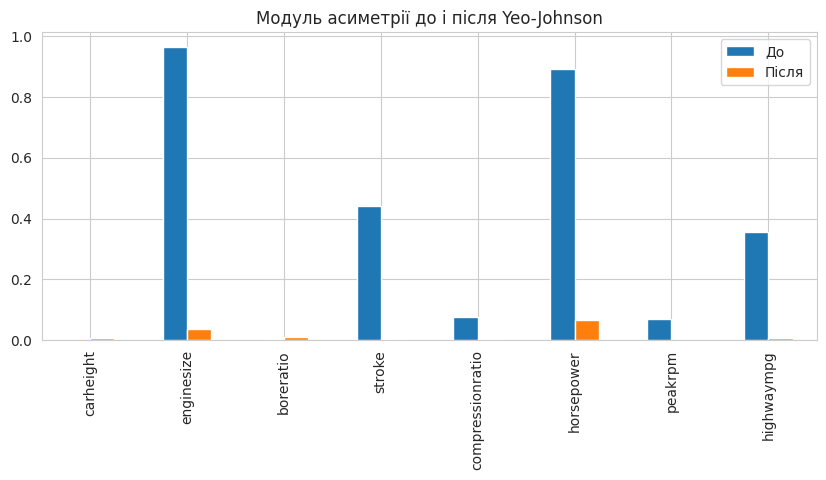

In [25]:
compare_skew.abs().plot(kind="bar", figsize=(10, 4))
plt.title("Модуль асиметрії до і після Yeo-Johnson")
plt.show()

Висновок: після трансформації асиметрія майже зникла. Наприклад, у enginesize вона зменшилась з 0.965 до 0.035, у horsepower з 0.893 до 0.067. Усі значення після перетворення близькі до нуля, отже трансформація спрацювала добре.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [26]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=5),
    "Lasso": Lasso(alpha=10, max_iter=50000),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=1),
    "SVR": SVR(C=100000, epsilon=100),   # великий C, бо ціни великі
}

pipelines = {name: make_pipeline(build_preprocessing(), reg) for name, reg in regressors.items()}
print(list(pipelines.keys()))

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting', 'SVR']


Висновок: побудовано 6 моделей, кожна в Pipeline з однаковою обробкою даних. Для Ridge взято alpha=5, для Lasso alpha=10, у Random Forest і Gradient Boosting по 300 дерев. Для SVR взято великий C=100000, бо ціни мають великі значення.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [27]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

table = []
test_preds = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    test_preds[name] = pred
    table.append([name,
                  r2_score(y_test, pred),
                  mean_absolute_error(y_test, pred),
                  mean_squared_error(y_test, pred),
                  100 * mean_absolute_percentage_error(y_test, pred),
                  r2_score(y_train, pipe.predict(X_train))])

metrics_df = pd.DataFrame(table, columns=["Модель", "R2", "MAE", "MSE", "MAPE %", "R2 train"])
metrics_df = metrics_df.sort_values("R2", ascending=False).reset_index(drop=True)
metrics_df.round(3)

,Модель,R2,MAE,MSE,MAPE %,R2 train
0,Random Forest,0.891,1574.333,5.973318e+06,11.387,0.986
1,Gradient Boosting,0.875,1587.369,6.888755e+06,11.035,0.992
2,SVR,0.845,1942.977,8.530900e+06,15.643,0.991
3,Lasso,0.825,1897.989,9.595235e+06,14.170,0.950
4,Linear Regression,0.821,1971.709,9.811789e+06,15.636,0.955
5,Ridge,0.807,2103.430,1.062672e+07,17.503,0.906


Висновок: найкращий R2 у Random Forest (0.891, MAE 1574, MAPE 11.4%). Дуже близько Gradient Boosting (R2 0.875), у нього навіть трохи менший MAPE (11.0%). SVR має R2 0.845. Лінійні моделі найслабші: Lasso 0.825, Linear Regression 0.821, Ridge 0.807. На train у дерев і SVR R2 близько 0.99, а на test менше, тобто є перенавчання.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Відповідь:

Ціна автомобіля це неперервне число, тому прогноз price це задача регресії.

Logistic Regression це модель для класифікації. Вона визначає, до якого класу належить об'єкт, і видає ймовірність від 0 до 1. Конкретну ціну вона не прогнозує. Щоб її використати, треба було б поділити авто на групи, наприклад дешеві і дорогі, але тоді ми втратимо точну ціну.

Моделі в цій роботі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR) регресійні. Вони видають число і намагаються зробити помилку між прогнозом і реальною ціною якомога меншою, тому вони підходять.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


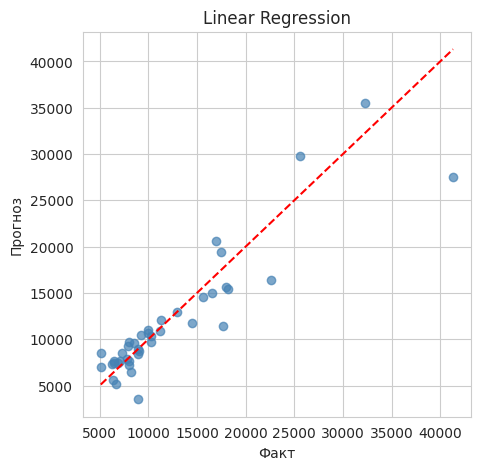

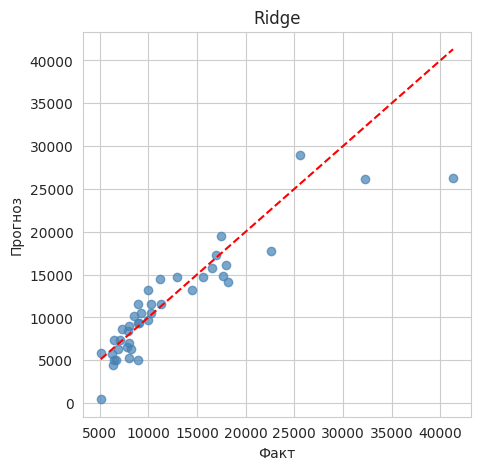

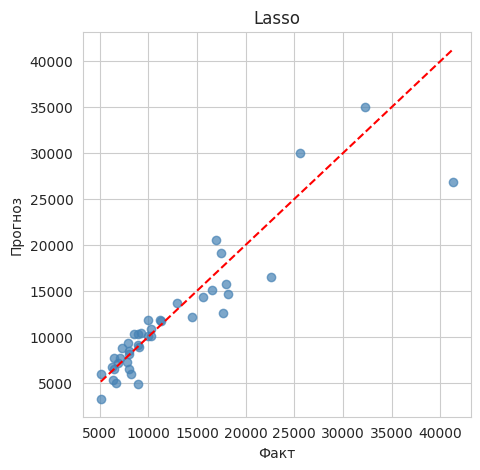

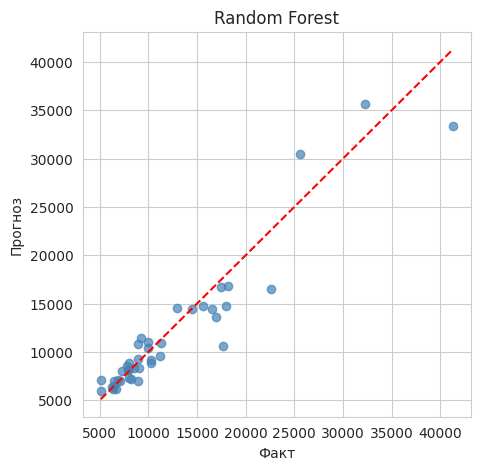

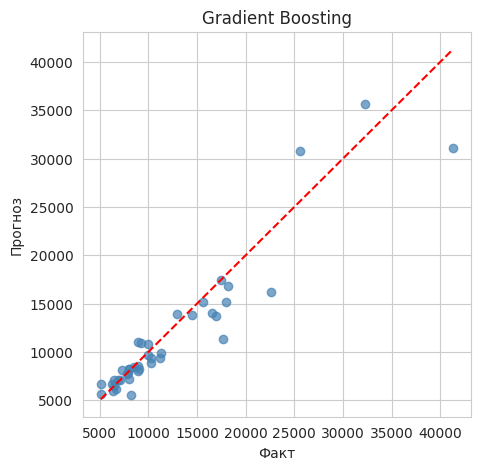

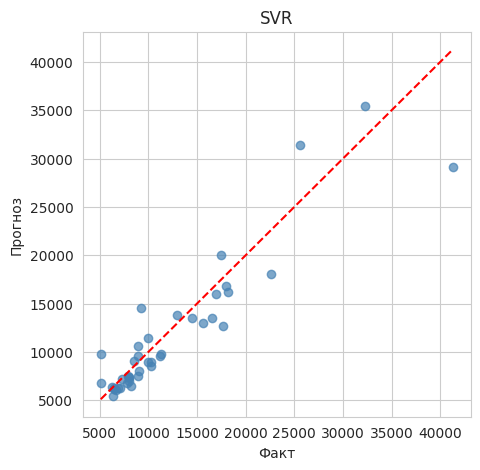

In [28]:
for name, pred in test_preds.items():
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, pred, color="steelblue", alpha=0.7)
    line = [y_test.min(), y_test.max()]
    plt.plot(line, line, color="red", linestyle="--")
    plt.title(name)
    plt.xlabel("Факт")
    plt.ylabel("Прогноз")
    plt.show()

In [29]:
# найбільша помилка для кожної моделі
for name, pred in test_preds.items():
    err = np.abs(y_test.values - pred)
    k = err.argmax()
    print(f"{name}: car_ID {ids_test.values[k]}, факт {y_test.values[k]:.0f}, прогноз {pred[k]:.0f}, помилка {err[k]:.0f}")

Linear Regression: car_ID 17, факт 41315, прогноз 27551, помилка 13764
Ridge: car_ID 17, факт 41315, прогноз 26273, помилка 15042
Lasso: car_ID 17, факт 41315, прогноз 26838, помилка 14477
Random Forest: car_ID 17, факт 41315, прогноз 33357, помилка 7958
Gradient Boosting: car_ID 17, факт 41315, прогноз 31071, помилка 10244
SVR: car_ID 17, факт 41315, прогноз 29149, помилка 12166


Висновок: у Random Forest і Gradient Boosting точки найближче до лінії ідеального прогнозу, у лінійних моделей розкид більший. Усі моделі найбільше помилились на одному авто, car_ID 17 з ціною 41315. Linear Regression дала для нього 27551 (помилка 13764), Random Forest 33357 (помилка 7958). Це дуже дороге авто, а таких у даних мало.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [30]:
rf = pipelines["Random Forest"]
rand10 = X_test.sample(n=10, random_state=10)

result10 = pd.DataFrame({
    "car_ID": ids_test[rand10.index].values,
    "Фактична ціна": y_test[rand10.index].values,
    "Прогнозована ціна": rf.predict(rand10).round(0),
})
result10["Абсолютна помилка"] = (result10["Фактична ціна"] - result10["Прогнозована ціна"]).abs()
result10["Абсолютна відсоткова помилка %"] = (result10["Абсолютна помилка"] / result10["Фактична ціна"] * 100).round(2)
result10

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка %
0,164,8058.0,8276.0,218.0,2.71
1,198,16515.0,14443.0,2072.0,12.55
2,131,9295.0,11449.0,2154.0,23.17
3,152,6338.0,6208.0,130.0,2.05
4,174,8948.0,10862.0,1914.0,21.39
5,34,6529.0,6978.0,449.0,6.88
6,137,18150.0,16821.0,1329.0,7.32
7,19,5151.0,5959.0,808.0,15.69
8,185,7995.0,8814.0,819.0,10.24
9,39,9095.0,8363.0,732.0,8.05


In [31]:
print("Середня відсоткова помилка:", result10["Абсолютна відсоткова помилка %"].mean().round(2), "%")

Середня відсоткова помилка: 11.0 %


Висновок: для 10 випадкових авто середня відсоткова помилка Random Forest 11%, середня абсолютна помилка приблизно 1063. Найточніше вгадано ціну для car_ID 152 (2.05%) і car_ID 164 (2.71%). Найбільші помилки у car_ID 131 (23.17%) і car_ID 174 (21.39%). Для більшості машин прогноз непоганий.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Загальний висновок:

1. Побудовано 6 моделей: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting і SVR, всі з однаковою передобробкою.

2. Найкращий результат за R2 у Random Forest: R2 = 0.891, MAE = 1574, MAPE = 11.4%. Gradient Boosting майже такий самий (R2 = 0.875, MAPE = 11.0%). Лінійні моделі слабші, R2 від 0.807 до 0.825.

3. Середня помилка найкращої моделі приблизно 1574, це близько 11% від ціни. Найбільші помилки у дорогих автомобілів, бо їх у даних мало.

4. На train у Random Forest, Gradient Boosting і SVR R2 близько 0.99, а на test від 0.85 до 0.89. Це означає, що є перенавчання, скоріше за все через малу кількість даних.

5. Передобробка допомогла: виправлено назви марок, викиди обмежено без видалення рядків, прибрано 5 сильно корельованих ознак, асиметрія після Yeo-Johnson стала майже нульовою. Усі параметри обробки рахувались тільки за train.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
